[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_lasso_path/BA_L5_lasso_path.ipynb)

# BA_L5_lasso_path: One Quantile Lasso equation: USDC after SVB

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Coefficient path, generalised approximate cross-validation (GACV) criterion and active-set size of a 5% Quantile Lasso for USD Coin (USDC) on the 90 days to 19 March 2023, with 9 other stablecoins and 4 lagged market variables as predictors (EODHD data).

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## One equation of the De-pegging Pressure Index: USD Coin (USDC) after Silicon Valley Bank (SVB)

Target: the reference-adjusted deviation of USDC on the 90 days to 19 March 2023; 13 candidate predictors: the deviations of the 9 other stablecoins (same day) and the one-day-lagged changes of the US dollar index (DXY), the CBOE volatility index (VIX), the S&P 500 index (SPX) and the 1-year Treasury yield (US1Y).

**Reference adjustment.** Let $P_{i,t}$ be the dollar price of token $i$ and $B_{i,t}$ the dollar value of its reference asset ($B = 1$ for dollar tokens, EUR/USD for STASIS Euro (EURS), XAU/USD for Pax Gold (PAXG)). The reference-adjusted deviation, in basis points (bp, 0.01%), is
$$ d_{i,t} = 10^4\left(\frac{P_{i,t}}{B_{i,t}} - 1\right). $$
Prices are put on a calendar of all days and filled from the past for at most 7 days; a daily move beyond 1,000 bp that reverses by at least 90% the next day is treated as a recording error and removed.

**5% Quantile Lasso.** With $\rho_\tau(e) = e\,(\tau - \mathbb 1\{e < 0\})$ and every variable centred by its window median and divided by $1.4826 \times$ its median absolute deviation (MAD),
$$ (\hat\alpha, \hat\beta)(\lambda) = \arg\min_{\alpha, \beta} \sum_{s} \rho_{0.05}\big(y_s - \alpha - \mathbf x_s'\beta\big) + \lambda \sum_k |\beta_k| . $$
All slopes are zero for $\lambda \geq \lambda_{max} = \max_k |\sum_s x_{k,s}(\tau - \mathbb 1\{y_s < \hat q_\tau\})|$. The penalty is chosen on 25 values from $10^{-4}\lambda_{max}$ to $\lambda_{max}$ by the generalised approximate cross-validation (GACV) criterion
$$ \mathrm{GACV}(\lambda) = \frac{\sum_s \rho_\tau\big(y_s - \hat\alpha - \mathbf x_s'\hat\beta(\lambda)\big)}{n - \mathrm{df}(\lambda)}, \qquad \mathrm{df} = \#\{\hat\beta_k \neq 0\} + 1 . $$

**How to read the chart.** Left: the coefficient path $\hat\beta_k(\lambda)$ (solid: coins, dashed: market variables); the dotted line is the selected $\hat\lambda$. Right: GACV and the number of active predictors (right scale).

In [4]:
# Data: 10 stablecoins, their reference assets and four market variables, 1 January 2020 - 23 October 2026
import matplotlib
plt.rcParams['font.size'] = 10
END, END_PAPER = '2026-10-23', '2026-05-31'          # last day of the lecture sample; last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def weekdays(x):
    """EUR/USD and gold: Monday-Friday closes, repeated closes removed (the weekend bars come from a thin session)."""
    x = x[x.index.dayofweek < 5]
    return x[x.diff() != 0]


def finish_fig(fig, name, bottom, ncol=3):
    """Legend below the plot, then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


ref = {'EURS': weekdays(daily('EURUSD.FOREX', END)), 'PAXG': weekdays(daily('XAUUSD.FOREX', END))}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)      # bad print: a move beyond 1000 bp, reversed by >= 90% the next day
P_raw = P.copy()                                           # prices as recorded
P = P.mask(bad).ffill(limit=7)                             # retrospective cleaning
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
D = 1e4 * (P / Bm - 1)                                     # reference-adjusted deviation d (bp)
D_raw = 1e4 * (P_raw / Bm - 1)                             # same, prices as recorded
R = 1e4 * np.log(P / Bm).diff()                            # reference-adjusted log return (bp)
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)     # market changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {int(bad.values.sum())}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


In [5]:
# 5% Quantile Lasso, penalty chosen by GACV, one equation per coin and day
from scipy.optimize import linprog
from joblib import Parallel, delayed
TAU, WIN, NGRID, LO = 0.05, 90, 25, 1e-4      # quantile level, window (days), grid size, lowest penalty / lambda_max
N_JOBS = os.cpu_count() or 1


def rho(e, tau=TAU):
    """Check loss."""
    return e * (tau - (e < 0))


def qlasso(X, y, lam):
    """Quantile Lasso as a linear programme: y = a+ - a- + X(b+ - b-) + u - v, minimise lam |b| + tau u + (1 - tau) v."""
    n, p = X.shape
    c = np.concatenate([[0, 0], lam * np.ones(2 * p), TAU * np.ones(n), (1 - TAU) * np.ones(n)])
    A = np.hstack([np.ones((n, 1)), -np.ones((n, 1)), X, -X, np.eye(n), -np.eye(n)])
    z = linprog(c, A_eq=A, b_eq=y, bounds=[(0, None)] * len(c), method='highs').x
    return z[0] - z[1], z[2:2 + p] - z[2 + p:2 + 2 * p]


def robust(Z):
    """Centre by the median, divide by 1.4826 x MAD (by the sd if the MAD is zero); drop constant columns."""
    med = np.median(Z, axis=0)
    mad = 1.4826 * np.median(np.abs(Z - med), axis=0)
    s = np.where(mad > 0, mad, Z.std(axis=0))
    keep = s > 0
    return (Z[:, keep] - med[keep]) / s[keep], keep


def fit_eq(y, X, lo=LO):
    """GACV-selected penalty on 25 values in [lo, 1] x lambda_max: returns (lambda, GACV, slopes, grid position)."""
    n = len(y)
    if X.shape[1] == 0:
        return np.nan, rho(y - np.quantile(y, TAU)).sum() / (n - 1), np.array([]), -1
    lmax = np.abs(X.T @ (TAU - (y < np.quantile(y, TAU)))).max()
    best = None
    for k, lam in enumerate(np.geomspace(lmax * lo, lmax, NGRID)):
        a, b = qlasso(X, y, lam)
        df = 1 + (np.abs(b) > 1e-8).sum()
        g = rho(y - a - X @ b).sum() / (n - df)
        if best is None or g < best[1]:
            best = (lam, g, b, k)
    return best


def window(t_idx):
    """Deviations of the 90 days before day t as known on day t: cleaned, except the last day (not yet checkable)."""
    Dw = D.iloc[t_idx - WIN:t_idx].copy()
    Dw.iloc[-1] = D_raw.iloc[t_idx - 1]
    return Dw


def day(t_idx, blocks=('coin', 'macro'), lo=LO):
    """All coin equations of calendar row t_idx: target d_j, predictors the other coins' d and the lagged market changes."""
    Dw = window(t_idx)
    out = {}
    for c in COINS:
        y = Dw[c].values
        if np.isnan(y).any():
            continue
        y = (y - np.median(y)) / (1.4826 * np.median(np.abs(y - np.median(y))) or y.std() or 1)
        parts, names = [], []
        if 'coin' in blocks:
            Xc = Dw.drop(columns=c)
            ok = ~np.isnan(Xc.values).any(axis=0)
            parts.append(Xc.values[:, ok]); names += list(Xc.columns[ok])
        if 'macro' in blocks:
            parts.append(M.values[t_idx - WIN:t_idx]); names += list(M.columns)
        Zs, keep = robust(np.hstack(parts))
        names = [nm for nm, k in zip(names, keep) if k]
        lam, g, b, k = fit_eq(y, Zs, lo)
        out[c] = dict(lam=lam, gacv=g, k=k, coef=dict(zip(names, b)))
    return t_idx, out


def run_days(idx, lo=LO):
    """Estimate all equations on the calendar rows idx, in parallel on all processor cores."""
    chunks = [c for c in np.array_split(np.asarray(idx), 4 * N_JOBS) if len(c)]
    out = Parallel(n_jobs=N_JOBS)(delayed(lambda ix: [day(i, lo=lo) for i in ix])(c) for c in chunks)
    return {i: o for part in out for i, o in part}


first = cal.get_loc(pd.Timestamp('2020-04-01'))           # first DPI day: 90 days of history
weekly = [i for i in range(first, len(cal)) if (cal[i] - pd.Timestamp('2020-06-29')).days % 7 == 0]   # days before the rebalancings

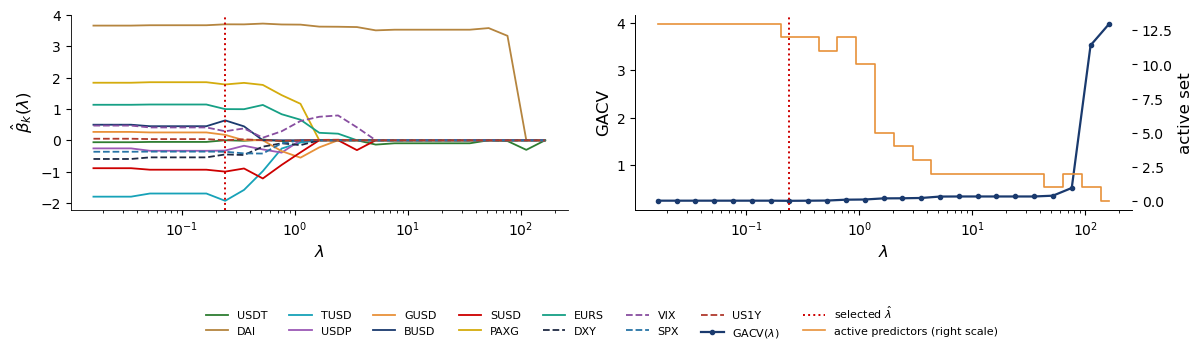

In [6]:
t_idx = cal.get_loc(pd.Timestamp('2023-03-20'))
w = slice(t_idx - WIN, t_idx)                              # the 90 days to 19 March 2023
y = D['USDC'].values[w]
y = (y - np.median(y)) / (1.4826 * np.median(np.abs(y - np.median(y))))
names = list(D.drop(columns='USDC').columns) + list(M.columns)
Zs, keep = robust(np.hstack([D.drop(columns='USDC').values[w], M.values[w]]))
names = [nm for nm, k in zip(names, keep) if k]
lmax = np.abs(Zs.T @ (TAU - (y < np.quantile(y, TAU)))).max()
grid = np.geomspace(lmax * LO, lmax, NGRID)
path, gac, dfs = [], [], []
for lam in grid:
    a, b = qlasso(Zs, y, lam)
    df = 1 + (np.abs(b) > 1e-8).sum()
    path.append(b); gac.append(rho(y - a - Zs @ b).sum() / (len(y) - df)); dfs.append(df - 1)
path = np.array(path); kb = int(np.argmin(gac))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
pal = [GREEN, GOLD, TEAL, ETH, BTC, BLUE, RED, '#D4AC0D', '#16A085', NAVY, '#884EA0', '#2874A6', '#B03A2E']
for j, nm in enumerate(names):
    ax[0].plot(grid, path[:, j], color=pal[j % len(pal)], lw=1.3, ls='-' if nm in COINS else '--', label=nm)
ax[0].axvline(grid[kb], color=RED, ls=':', lw=1.4)
ax[0].set_xscale('log'); ax[0].set_xlabel(r'$\lambda$'); ax[0].set_ylabel(r'$\hat\beta_k(\lambda)$')
ax[1].plot(grid, gac, color=BLUE, lw=1.6, marker='o', ms=3, label=r'GACV($\lambda$)')
ax[1].axvline(grid[kb], color=RED, ls=':', lw=1.4, label=r'selected $\hat\lambda$')
ax2 = ax[1].twinx(); ax2.spines['top'].set_visible(False)
ax2.step(grid, dfs, color=BTC, where='mid', lw=1.2, label='active predictors (right scale)')
ax[1].set_xscale('log'); ax[1].set_xlabel(r'$\lambda$'); ax[1].set_ylabel('GACV'); ax2.set_ylabel('active set')
finish_fig(fig, 'ba_l5_lasso_path', 0.2, ncol=8)

In [7]:
print(f'lambda_max = {lmax:.1f}; selected lambda = {grid[kb]:.3f}; active predictors: {dfs[kb]} of {len(names)}; minimum GACV = {gac[kb]:.4f}')
pd.Series({nm: v for nm, v in zip(names, path[kb]) if abs(v) > 1e-8}).sort_values(key=abs, ascending=False).round(2).to_frame('slope at the selected lambda')

lambda_max = 164.1; selected lambda = 0.241; active predictors: 12 of 13; minimum GACV = 0.2561


,slope at the selected lambda
DAI,3.70
TUSD,-1.93
PAXG,1.78
SUSD,-1.00
EURS,0.99
BUSD,0.63
DXY,-0.45
SPX,-0.37
USDP,-0.33
VIX,0.29


DAI keeps the largest slope along the path and is the only active predictor at $\lambda \approx 52$ (USDT enters first, alone, at $\lambda \approx 112$; DAI enters at $\lambda \approx 76$): in the SVB window, the lower tail of USDC was the lower tail of DAI.